# RNF05 — gráficos das rodadas

Issue #231 (S4-35). Gera as figuras da Seção 9.2.7 do `Projeto.md` a partir dos CSVs
do Locust versionados neste diretório. Nenhum número é digitado à mão: tudo sai de
`*_stats.csv`, o resumo final que o Locust grava ao fim de cada rodada.

Dependências: `pandas` e `matplotlib`, as mesmas de `src/notebooks/requirements.txt`.
Executar a partir de `src/backend/evidencias`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

BASE = Path('.')
SAIDA = Path('../../../docs/img')
TETO = {'simples': 10.0, 'comparacao': 20.0}
NOME_DA_ROTA = {'simples': 'simples', 'comparacao': 'comparação'}

## Leitura dos CSVs

Cada rodada tem um `*_stats.csv` com uma linha por rota (`[simples]` e `[comparacao]`)
e uma linha agregada. Os percentis estão em milissegundos.

In [2]:
RODADAS = [
    ('1ª · 1 usuário', 'rnf05-37flash/baseline/rnf05-baseline_stats.csv'),
    ('1ª · 5 usuários', 'rnf05-37flash/carga/rnf05-carga_stats.csv'),
    ('2ª · 1 usuário', 'rnf05-rodada2/baseline/rnf05-baseline_stats.csv'),
    ('2ª · 5 usuários', 'rnf05-rodada2/carga/rnf05-carga_stats.csv'),
    ('3ª · 1 usuário (35 min)', 'rnf05-rodada3/baseline-estendida/rnf05-baseline_stats.csv'),
    ('3ª · 5 usuários', 'rnf05-rodada3/carga/rnf05-carga_stats.csv'),
    ('3ª · frio · 1 usuário (35 min)', 'rnf05-rodada3/cache-frio/baseline/rnf05-baseline_stats.csv'),
    ('3ª · frio · 5 usuários', 'rnf05-rodada3/cache-frio/carga/rnf05-carga_stats.csv'),
]


def ler(caminho):
    tabela = pd.read_csv(BASE / caminho)
    tabela = tabela[tabela['Name'].str.contains(r'\[', regex=True)].copy()
    tabela['rota'] = tabela['Name'].str.extract(r'\[(\w+)\]', expand=False)
    return tabela.set_index('rota')


linhas = []
for rotulo, caminho in RODADAS:
    tabela = ler(caminho)
    for rota in ('simples', 'comparacao'):
        linha = tabela.loc[rota]
        linhas.append({
            'rodada': rotulo,
            'rota': rota,
            'amostras': int(linha['Request Count']),
            'falhas': int(linha['Failure Count']),
            'p95_s': linha['95%'] / 1000,
        })
resumo = pd.DataFrame(linhas)
resumo

,rodada,rota,amostras,falhas,p95_s
0,1ª · 1 usuário,simples,24,0,6.6
1,1ª · 1 usuário,comparacao,10,0,38.0
2,1ª · 5 usuários,simples,165,0,7.1
3,1ª · 5 usuários,comparacao,43,0,8.0
4,2ª · 1 usuário,simples,123,1,9.3
5,2ª · 1 usuário,comparacao,41,0,12.0
6,2ª · 5 usuários,simples,202,0,11.0
7,2ª · 5 usuários,comparacao,72,0,11.0
8,3ª · 1 usuário (35 min),simples,181,0,7.6
9,3ª · 1 usuário (35 min),comparacao,82,0,8.4


## Figura 1 — P95 por rodada e rota

As barras são o P95 de cada rota; as linhas tracejadas, os tetos do RNF05. As duas últimas barras são as janelas de cache frio da 3ª rodada, com a API reiniciada e sem aquecimento. Rodadas com
falha recebem a anotação ao lado da barra, porque o requisito exige zero erro
independentemente do P95. A 1ª rodada não tinha amostra mínima, o que faz o P95 da
comparação com um usuário coincidir com a pior requisição (Seção 9.2.4).

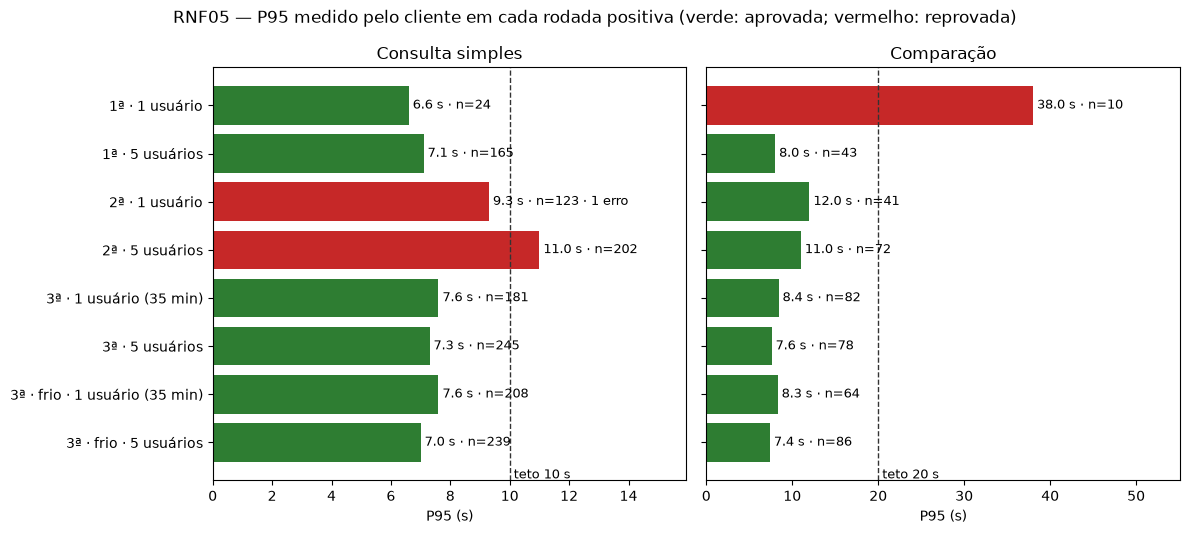

In [3]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5.4), sharey=False)
for eixo, rota, titulo in [
    (eixos[0], 'simples', 'Consulta simples'),
    (eixos[1], 'comparacao', 'Comparação'),
]:
    dados = resumo[resumo['rota'] == rota].reset_index(drop=True)
    cores = ['#2e7d32' if (p <= TETO[rota] and f == 0) else '#c62828'
             for p, f in zip(dados['p95_s'], dados['falhas'])]
    barras = eixo.barh(dados['rodada'], dados['p95_s'], color=cores)
    eixo.axvline(TETO[rota], color='#333', linestyle='--', linewidth=1)
    eixo.text(TETO[rota], len(dados) - 0.45, f' teto {TETO[rota]:.0f} s', va='top', fontsize=9)
    for barra, (_, linha) in zip(barras, dados.iterrows()):
        nota = f" {linha['p95_s']:.1f} s · n={linha['amostras']}"
        if linha['falhas']:
            nota += f" · {linha['falhas']} erro"
        eixo.text(barra.get_width(), barra.get_y() + barra.get_height() / 2, nota,
                  va='center', fontsize=9)
    eixo.set_title(titulo)
    eixo.set_xlabel('P95 (s)')
    eixo.set_xlim(0, max(dados['p95_s'].max(), TETO[rota]) * 1.45)
    eixo.invert_yaxis()
eixos[1].set_yticklabels([])
fig.suptitle('RNF05 — P95 medido pelo cliente em cada rodada positiva (verde: aprovada; vermelho: reprovada)')
fig.tight_layout()
SAIDA.mkdir(parents=True, exist_ok=True)
fig.savefig(SAIDA / 'rnf05-p95-rodadas.png', dpi=150, bbox_inches='tight')
plt.show()

## Figura 2 — perfil de percentis da 3ª rodada e cenário negativo

Mediana, P90, P95, P99 e máximo de cada janela da 3ª rodada, por rota, ao lado do
cenário negativo (`CT-RNF05-N`), em que um duplo injeta 25 s de atraso em toda
comparação. O negativo precisa ficar acima do teto: é a prova de que a medição
enxerga a violação.

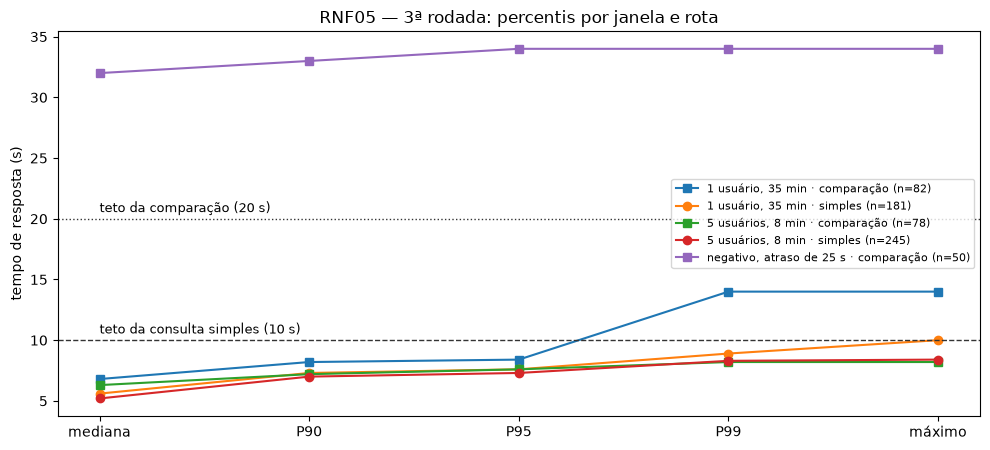

In [4]:
JANELAS = [
    ('1 usuário, 35 min', 'rnf05-rodada3/baseline-estendida/rnf05-baseline_stats.csv'),
    ('5 usuários, 8 min', 'rnf05-rodada3/carga/rnf05-carga_stats.csv'),
    ('negativo, atraso de 25 s', 'rnf05-rodada3/violacao/rnf05-violacao_stats.csv'),
]
PERCENTIS = [('50%', 'mediana'), ('90%', 'P90'), ('95%', 'P95'), ('99%', 'P99'), ('100%', 'máximo')]
# O Locust arredonda os percentis a dois algarismos significativos; o maximo
# exato de cada rota esta na coluna 'Max Response Time' do mesmo CSV.

fig, eixo = plt.subplots(figsize=(10, 4.6))
estilos = {'simples': '-o', 'comparacao': '-s'}
for rotulo, caminho in JANELAS:
    tabela = ler(caminho)
    for rota in tabela.index:
        valores = [tabela.loc[rota, coluna] / 1000 for coluna, _ in PERCENTIS]
        eixo.plot([nome for _, nome in PERCENTIS], valores, estilos[rota],
                  label=f'{rotulo} · {NOME_DA_ROTA[rota]} (n={int(tabela.loc[rota, "Request Count"])})')
eixo.axhline(10, color='#333', linestyle='--', linewidth=1)
eixo.axhline(20, color='#333', linestyle=':', linewidth=1)
eixo.text(0, 10.3, 'teto da consulta simples (10 s)', va='bottom', fontsize=9)
eixo.text(0, 20.3, 'teto da comparação (20 s)', va='bottom', fontsize=9)
eixo.set_ylabel('tempo de resposta (s)')
eixo.set_title('RNF05 — 3ª rodada: percentis por janela e rota')
eixo.legend(fontsize=8, loc='center right')
fig.tight_layout()
fig.savefig(SAIDA / 'rnf05-rodada3-percentis.png', dpi=150, bbox_inches='tight')
plt.show()